# 02: EDA Data Bersih & Analisis Lanjutan

**Tujuan:** Menganalisis karakteristik penjualan ITA Cake Shop secara mendalam menggunakan data transaksi yang telah dibersihkan, memvalidasi karakteristik statistik deret waktu (sparsitas, profil variasi permintaan, justifikasi empiris model multiplikatif, autokorelasi musiman, serta dekomposisi runtun waktu), dan memetakan pola operasional (kinerja Pareto produk, tren kuartalan, lonjakan akhir pekan, jam sibuk transaksi, serta proporsi hari) guna menyiapkan landasan kokoh bagi pemodelan peramalan produksi di tahap *downstream*.

In [1]:
import os
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr
from statsmodels.tsa.stattools import adfuller, acf
from statsmodels.tsa.seasonal import seasonal_decompose

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')

# ------------------------------------------------------------------------------
# 1. SETUP DIREKTORI & LOAD DATASET
# ------------------------------------------------------------------------------
def resolve_base_directory():
    cwd = Path.cwd()
    candidates = [
        cwd,
        cwd / 'FINAL_BERSIH' / '01_data_ITA-Cake-Shop',
        cwd / 'Skripsi[revisifinal]',
        cwd.parent / 'FINAL_BERSIH' / '01_data_ITA-Cake-Shop',
        Path(r'c:\Users\admin\Documents\Semester 8 & 9\Skripsi(2)\FINAL_BERSIH\01_data_ITA-Cake-Shop')
    ]
    for p in candidates:
        if (p / 'Data_Output' / 'Master_Clean_Feb2023_Feb2026.csv').exists() or \
           (p / 'Master Data Final' / 'Master_Clean_Feb2023_Feb2026.csv').exists():
            return p
    return cwd

BASE_DIR = resolve_base_directory()
DATA_DIR = BASE_DIR / 'Data_Output'
LEGACY_DIR = BASE_DIR / 'Master Data Final'
FIG_DIR = BASE_DIR / 'Visualisasi_Gambar'
IMG_DIR = FIG_DIR

FIG_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR.mkdir(parents=True, exist_ok=True)

def get_csv_path(filename):
    if (DATA_DIR / filename).exists():
        return DATA_DIR / filename
    if (LEGACY_DIR / filename).exists():
        return LEGACY_DIR / filename
    raise FileNotFoundError(f'File {filename} tidak ditemukan di {DATA_DIR} maupun {LEGACY_DIR}')

df_skripsi = pd.read_csv(get_csv_path('Master_Clean_Feb2023_Feb2026.csv'), parse_dates=['order date'])
df_ext = pd.read_csv(get_csv_path('Master_Clean_Feb2023_Sept2026.csv'), parse_dates=['order date'])
weekly_clean = pd.read_csv(get_csv_path('weekly_clean_final.csv'), parse_dates=['date'], index_col='date')

# Alias df_feb untuk backward-compatibility dengan sel downstream
df_feb = df_skripsi

print(f'[*] Sukses memuat dataset Master Skripsi (Feb 2023 - Feb 2026): {df_skripsi.shape}')
print(f'[*] Sukses memuat dataset Master Extended (Feb 2023 - Sept 2026): {df_ext.shape}')
print(f'[*] Sukses memuat dataset Mingguan Bersih (weekly_clean_final.csv): {weekly_clean.shape}')

[*] Sukses memuat dataset Master Skripsi (Feb 2023 - Feb 2026): (106539, 12)
[*] Sukses memuat dataset Master Extended (Feb 2023 - Sept 2026): (125888, 12)
[*] Sukses memuat dataset Mingguan Bersih (weekly_clean_final.csv): (155, 3)


## 1. Overview Komparasi Dataset (Master Skripsi vs Master Extended)

Sebelum melangkah ke analisis statistik dan peramalan mendalam, bagian ini menyajikan perbandingan komprehensif antara dua versi dataset master bersih:
1. **Master Skripsi (Resmi):** Rentang 20 Februari 2023 hingga 9 Februari 2026 (1.086 hari / 155 minggu kontinu penuh). Versi ini adalah dataset primer yang digunakan untuk seluruh pengujian hipotesis, validasi model, dan penulisan skripsi akademik.
2. **Master Extended (Longitudinal):** Rentang 16 Februari 2023 hingga 10 September 2026 (1.303 hari). Versi ini digunakan untuk audit longitudinal dan verifikasi stabilitas data jangka panjang.

In [2]:
# ------------------------------------------------------------------------------
# OVERVIEW & KOMPARASI DUA VERSI DATASET MASTER BERSIH
# ------------------------------------------------------------------------------
target_cats = ['Cake', 'Japanese', 'Mille Crepes']

def generate_overview_metrics(df, name):
    min_date = df['order date'].min()
    max_date = df['order date'].max()
    total_days = (max_date - min_date).days + 1
    total_weeks = len(pd.date_range(min_date, max_date, freq='W-MON'))
    total_rows = len(df)
    
    rev_target = df[df['item group'].isin(target_cats)].groupby('item group')['omzet_bersih'].sum()
    total_target_rev = rev_target.sum()
    total_store_rev = df['omzet_bersih'].sum()
    
    return {
        'Versi Dataset': name,
        'Rentang Waktu': f"{min_date.strftime('%d/%m/%Y')} - {max_date.strftime('%d/%m/%Y')}",
        'Durasi (Hari)': total_days,
        'Durasi (Minggu)': total_weeks,
        'Total Transaksi': total_rows,
        'Omzet Cake': rev_target.get('Cake', 0),
        'Omzet Japanese': rev_target.get('Japanese', 0),
        'Omzet Mille Crepes': rev_target.get('Mille Crepes', 0),
        'Total Omzet 3 Kategori': total_target_rev,
        'Total Omzet Toko': total_store_rev,
        'Pangsa Omzet Target (%)': (total_target_rev / total_store_rev) * 100
    }

df_overview_summary = pd.DataFrame([
    generate_overview_metrics(df_skripsi, 'Master Skripsi (Resmi)'),
    generate_overview_metrics(df_ext, 'Master Extended (Longitudinal)')
])

# Render dengan Pandas Styler HTML
styled_overview = (
    df_overview_summary.style
    .format({
        'Durasi (Hari)': '{:,}',
        'Durasi (Minggu)': '{:,}',
        'Total Transaksi': '{:,}',
        'Omzet Cake': 'Rp {:,.0f}',
        'Omzet Japanese': 'Rp {:,.0f}',
        'Omzet Mille Crepes': 'Rp {:,.0f}',
        'Total Omzet 3 Kategori': 'Rp {:,.0f}',
        'Total Omzet Toko': 'Rp {:,.0f}',
        'Pangsa Omzet Target (%)': '{:.2f}%'
    })
    .set_caption('<b>Tabel 1: Ringkasan Metrik Komparasi Master Data Skripsi vs Extended</b>')
    .set_table_styles([
        {'selector': 'th', 'props': [('background-color', '#1f3a52'), ('color', 'white'), ('font-weight', 'bold'), ('text-align', 'center'), ('padding', '8px')]},
        {'selector': 'td', 'props': [('text-align', 'right'), ('padding', '6px 10px')]},
        {'selector': 'caption', 'props': [('caption-side', 'top'), ('font-size', '13px'), ('margin-bottom', '8px')]}
    ])
)
display(styled_overview)

,Versi Dataset,Rentang Waktu,Durasi (Hari),Durasi (Minggu),Total Transaksi,Omzet Cake,Omzet Japanese,Omzet Mille Crepes,Total Omzet 3 Kategori,Total Omzet Toko,Pangsa Omzet Target (%)
0,Master Skripsi (Resmi),20/02/2023 - 09/02/2026,"1,086",156,"106,539","Rp 1,083,361,292","Rp 648,643,368","Rp 313,958,301","Rp 2,045,962,961","Rp 4,045,367,745",50.58%
1,Master Extended (Longitudinal),16/02/2023 - 10/09/2026,"1,303",186,"125,888","Rp 1,317,546,289","Rp 709,569,593","Rp 335,416,131","Rp 2,362,532,013","Rp 4,929,900,345",47.92%


## 2. Analisis Kinerja Produk (Pareto & Klasifikasi ABC)

Menentukan kontribusi produk (SKU) terhadap omzet keseluruhan. Produk kelas A yang memberikan 80% revenue menjadi fokus utama pemodelan dan manajemen persediaan.

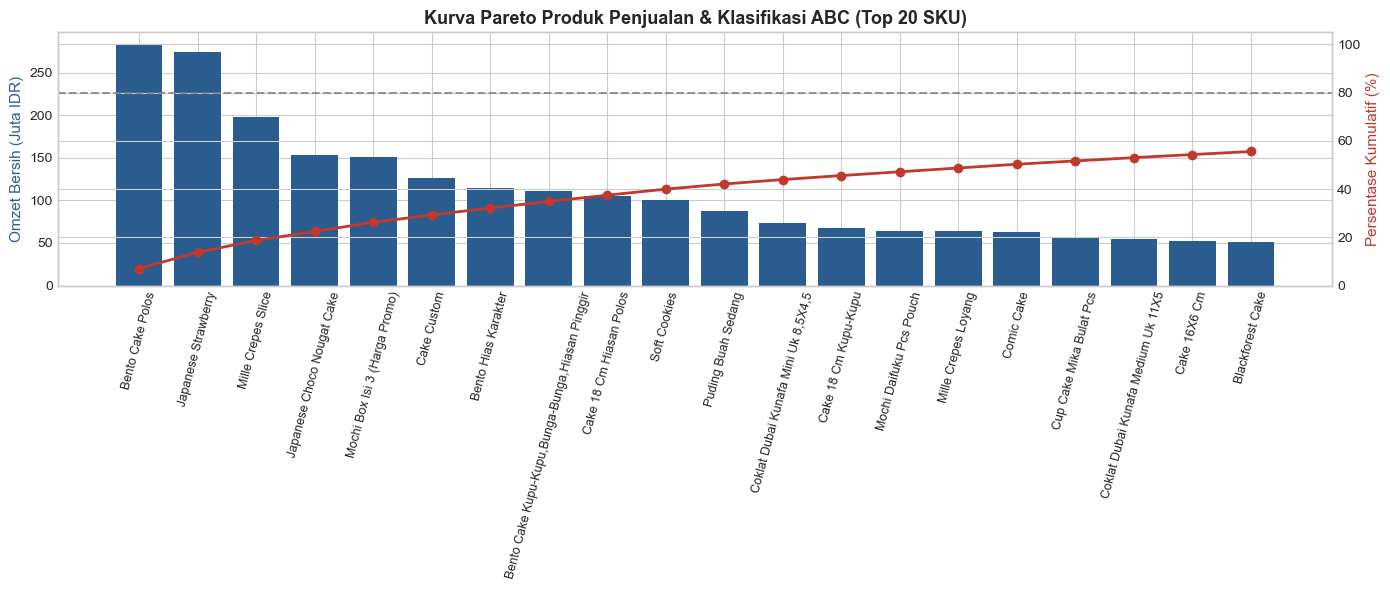

In [3]:
# ------------------------------------------------------------------------------
# 2. SKU-LEVEL PARETO & ABC CLASSIFICATION
# ------------------------------------------------------------------------------
sku_sales = df_feb.groupby('item name').agg(
    qty_total=('qty', 'sum'),
    omzet_bersih=('omzet_bersih', 'sum')
).reset_index().sort_values('omzet_bersih', ascending=False)

sku_sales['cum_omzet'] = sku_sales['omzet_bersih'].cumsum()
sku_sales['cum_share_%'] = 100 * sku_sales['cum_omzet'] / sku_sales['omzet_bersih'].sum()

def assign_abc(cum_pct):
    if cum_pct <= 80: return 'A'
    elif cum_pct <= 95: return 'B'
    return 'C'

sku_sales['class_abc'] = sku_sales['cum_share_%'].apply(assign_abc)

# Plot Dual-Axis Pareto for Top 20 SKUs
fig, ax1 = plt.subplots(figsize=(14, 6))
top20 = sku_sales.head(20)
ax1.bar(top20['item name'], top20['omzet_bersih'] / 1e6, color='#2b5c8f', label='Omzet (Juta Rp)')
ax1.set_ylabel('Omzet Bersih (Juta IDR)', color='#2b5c8f', fontsize=11)
ax1.tick_params(axis='x', rotation=75, labelsize=9)

ax2 = ax1.twinx()
ax2.plot(top20['item name'], top20['cum_share_%'], color='#c0392b', marker='o', linewidth=2, label='Kumulatif %')
ax2.axhline(80, color='gray', linestyle='--', alpha=0.8, label='Cutoff 80% (Kelas A)')
ax2.set_ylabel('Persentase Kumulatif (%)', color='#c0392b', fontsize=11)
ax2.set_ylim(0, 105)

plt.title('Kurva Pareto Produk Penjualan & Klasifikasi ABC (Top 20 SKU)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(FIG_DIR / 'pareto_sku_abc.png', dpi=300, bbox_inches='tight')
plt.show()

## 3. Analisis Pola Waktu Penjualan (Temporal Patterns)

Memetakan dinamika penjualan lintas skala waktu: tren makro kuartalan (*quarterly*), sensitivitas hari kerja versus akhir pekan (*weekday vs weekend*), jam-jam sibuk transaksi kasir (*peak hours*), serta distribusi proporsi hari dalam sepekan (*day-of-week*).

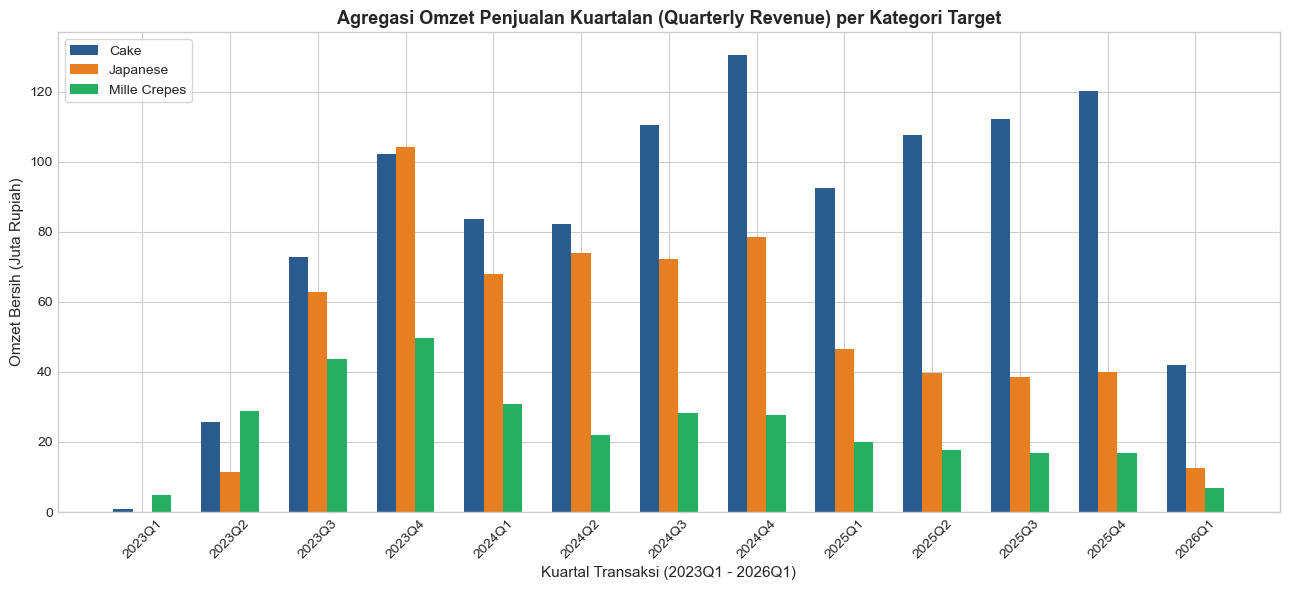

item group,Cake,Japanese,Mille Crepes,Total 3 Kategori,Total Toko
quarter,,,,,
2023Q1,"Rp 1,000,000",Rp 0,"Rp 4,832,000","Rp 5,832,000","Rp 11,213,500"
2023Q2,"Rp 25,735,000","Rp 11,425,000","Rp 28,816,000","Rp 65,976,000","Rp 129,353,000"
2023Q3,"Rp 72,798,000","Rp 62,935,000","Rp 43,559,000","Rp 179,292,000","Rp 278,937,800"
2023Q4,"Rp 102,137,000","Rp 104,290,000","Rp 49,802,000","Rp 256,229,000","Rp 440,641,000"
2024Q1,"Rp 83,663,000","Rp 67,915,000","Rp 30,823,000","Rp 182,401,000","Rp 355,002,000"
2024Q2,"Rp 82,304,000","Rp 73,877,000","Rp 22,066,000","Rp 178,247,000","Rp 336,595,500"
2024Q3,"Rp 110,514,000","Rp 72,354,000","Rp 28,265,000","Rp 211,133,000","Rp 387,347,800"
2024Q4,"Rp 130,428,500","Rp 78,408,500","Rp 27,830,000","Rp 236,667,000","Rp 552,230,500"
2025Q1,"Rp 92,516,000","Rp 46,555,000","Rp 19,878,000","Rp 158,949,000","Rp 363,672,800"


In [4]:
# ------------------------------------------------------------------------------
# 3.1 ANALISIS OMZET KUARTALAN (QUARTERLY REVENUE)
# ------------------------------------------------------------------------------
df_skripsi['quarter'] = df_skripsi['order date'].dt.to_period('Q').astype(str)

q_pivot = df_skripsi[df_skripsi['item group'].isin(target_cats)].pivot_table(
    index='quarter',
    columns='item group',
    values='omzet_bersih',
    aggfunc='sum',
    fill_value=0
)
q_pivot['Total 3 Kategori'] = q_pivot.sum(axis=1)
q_pivot['Total Toko'] = df_skripsi.groupby('quarter')['omzet_bersih'].sum()

# Plot Quarterly Revenue
plt.figure(figsize=(13, 6))
bar_width = 0.22
quarters = q_pivot.index
x = np.arange(len(quarters))

plt.bar(x - bar_width, q_pivot['Cake'] / 1e6, width=bar_width, label='Cake', color='#2b5c8f')
plt.bar(x, q_pivot['Japanese'] / 1e6, width=bar_width, label='Japanese', color='#e67e22')
plt.bar(x + bar_width, q_pivot['Mille Crepes'] / 1e6, width=bar_width, label='Mille Crepes', color='#27ae60')

plt.title('Agregasi Omzet Penjualan Kuartalan (Quarterly Revenue) per Kategori Target', fontsize=13, fontweight='bold')
plt.xlabel('Kuartal Transaksi (2023Q1 - 2026Q1)', fontsize=11)
plt.ylabel('Omzet Bersih (Juta Rupiah)', fontsize=11)
plt.xticks(x, quarters, rotation=45)
plt.legend(frameon=True, loc='upper left')
plt.tight_layout()
plt.savefig(FIG_DIR / 'quarterly_revenue_trend.png', dpi=300, bbox_inches='tight')
plt.savefig(FIG_DIR / 'quarterly_revenue.png', dpi=300, bbox_inches='tight')
plt.show()

# Render Styled Table Kuartalan
styled_quarterly = (
    q_pivot.style
    .format('Rp {:,.0f}')
    .set_caption('<b>Tabel 2: Rincian Omzet Penjualan Kuartalan (IDR)</b>')
    .set_table_styles([
        {'selector': 'th', 'props': [('background-color', '#2c3e50'), ('color', 'white'), ('font-weight', 'bold')]},
        {'selector': 'td', 'props': [('text-align', 'right'), ('padding', '5px 8px')]}
    ])
)
display(styled_quarterly)

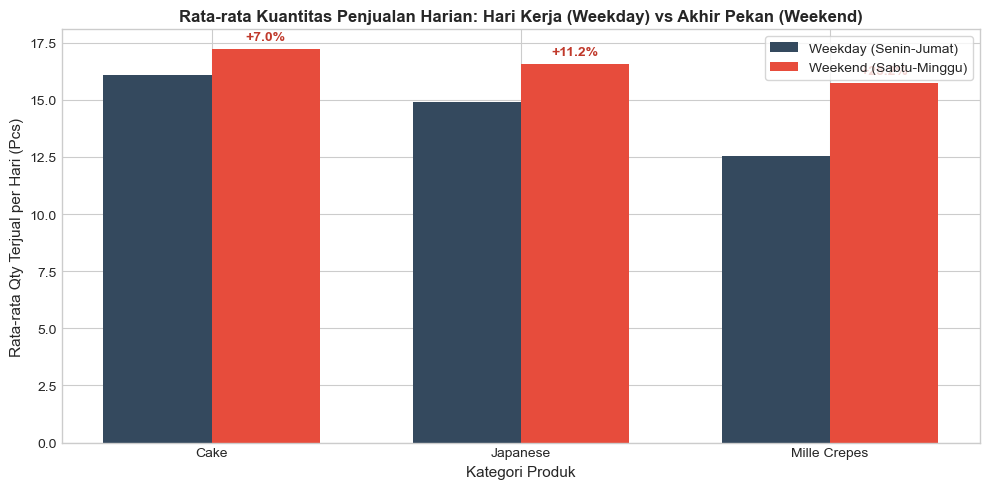

day_type,Weekday (Senin-Jumat),Weekend (Sabtu-Minggu),Weekend Lift (%)
item group,,,
Cake,16.09,17.21,+6.98%
Japanese,14.91,16.57,+11.17%
Mille Crepes,12.56,15.72,+25.18%


In [5]:
# ------------------------------------------------------------------------------
# 3.2 KOMPARASI PENJUALAN: HARI KERJA (WEEKDAY) VS AKHIR PEKAN (WEEKEND)
# ------------------------------------------------------------------------------
df_target = df_skripsi[df_skripsi['item group'].isin(target_cats)].copy()
df_target['dow'] = df_target['order date'].dt.dayofweek
df_target['day_type'] = df_target['dow'].apply(lambda x: 'Weekend (Sabtu-Minggu)' if x >= 5 else 'Weekday (Senin-Jumat)')

cat_day = df_target.groupby(['order date', 'day_type', 'item group'])['qty'].sum().reset_index()
pivot_lift = cat_day.groupby(['item group', 'day_type'])['qty'].mean().unstack()
pivot_lift['Weekend Lift (%)'] = ((pivot_lift['Weekend (Sabtu-Minggu)'] - pivot_lift['Weekday (Senin-Jumat)']) / pivot_lift['Weekday (Senin-Jumat)']) * 100

plt.figure(figsize=(10, 5))
x = np.arange(len(pivot_lift.index))
width = 0.35
plt.bar(x - width/2, pivot_lift['Weekday (Senin-Jumat)'], width, label='Weekday (Senin-Jumat)', color='#34495e')
plt.bar(x + width/2, pivot_lift['Weekend (Sabtu-Minggu)'], width, label='Weekend (Sabtu-Minggu)', color='#e74c3c')
plt.title('Rata-rata Kuantitas Penjualan Harian: Hari Kerja (Weekday) vs Akhir Pekan (Weekend)', fontsize=12, fontweight='bold')
plt.xlabel('Kategori Produk', fontsize=11)
plt.ylabel('Rata-rata Qty Terjual per Hari (Pcs)', fontsize=11)
plt.xticks(x, pivot_lift.index)
for i in range(len(pivot_lift)):
    lift_val = pivot_lift['Weekend Lift (%)'].iloc[i]
    plt.text(i + width/2, pivot_lift['Weekend (Sabtu-Minggu)'].iloc[i] + 0.4, f'+{lift_val:.1f}%', ha='center', fontweight='bold', color='#c0392b', fontsize=10)

plt.legend(frameon=True)
plt.tight_layout()
plt.savefig(FIG_DIR / 'weekday_vs_weekend_lift.png', dpi=300, bbox_inches='tight')
plt.savefig(FIG_DIR / 'weekday_vs_weekend.png', dpi=300, bbox_inches='tight')
plt.show()

styled_lift = (
    pivot_lift.style
    .format({'Weekday (Senin-Jumat)': '{:.2f}', 'Weekend (Sabtu-Minggu)': '{:.2f}', 'Weekend Lift (%)': '+{:.2f}%'})
    .set_caption('<b>Tabel 3: Perbandingan Rata-rata Kuantitas Harian & Lonjakan Akhir Pekan (Lift %)</b>')
)
display(styled_lift)

### 3.3 Analisis Peak Hour (2D Heatmap Hari x Jam)

Memetakan kepadatan transaksi berdasarkan hari dan jam operasional kasir. Temuan ini krusial untuk penjadwalan barista/koki serta pengawasan persediaan etalase pada jam sibuk.

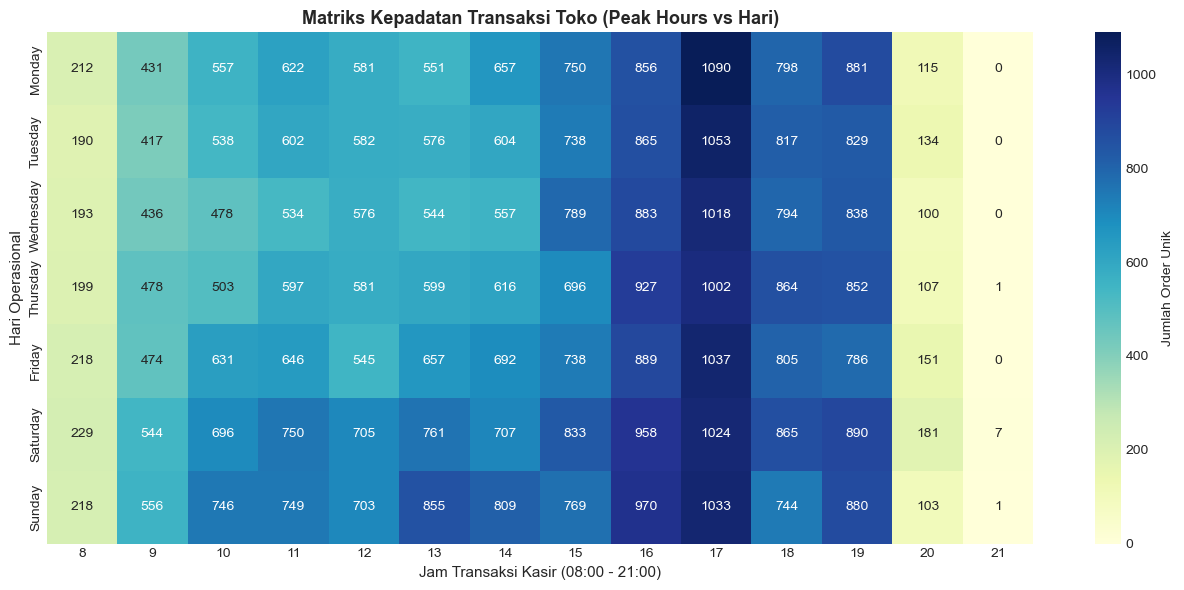

In [6]:
# ------------------------------------------------------------------------------
# 3.3 2D PEAK HOUR HEATMAP (DAY-OF-WEEK x HOUR)
# ------------------------------------------------------------------------------
df_feb['order_time_parsed'] = pd.to_datetime(df_feb['order time'], format='mixed', errors='coerce')
df_feb['order_hour'] = df_feb['order_time_parsed'].dt.hour
df_feb['dow_name'] = df_feb['order date'].dt.day_name()

dow_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
hourly_matrix = df_feb.pivot_table(
    index='dow_name', 
    columns='order_hour', 
    values='order no', 
    aggfunc='nunique'
).reindex(dow_order).fillna(0)

plt.figure(figsize=(13, 6))
sns.heatmap(hourly_matrix, cmap='YlGnBu', annot=True, fmt='.0f', cbar_kws={'label': 'Jumlah Order Unik'})
plt.title('Matriks Kepadatan Transaksi Toko (Peak Hours vs Hari)', fontsize=13, fontweight='bold')
plt.xlabel('Jam Transaksi Kasir (08:00 - 21:00)', fontsize=11)
plt.ylabel('Hari Operasional', fontsize=11)
plt.tight_layout()
plt.savefig(FIG_DIR / 'peak_hours_heatmap_2d.png', dpi=300, bbox_inches='tight')
plt.show()

### 3.4 Profil Proporsi Hari (Day-of-Week) untuk Disagregasi

Memetakan distribusi proporsi penjualan berdasarkan hari dalam sepekan, yang krusial untuk melakukan disagregasi target dari mingguan (*Weekly*) ke harian (*Daily*) di tingkat operasional produksi.

Day-of-Week Sales Proportion (%):
dow_name
Monday       13.641227
Tuesday      13.431597
Wednesday    13.466536
Thursday     13.743858
Friday       14.263566
Saturday     15.711322
Sunday       15.741893
Name: qty, dtype: float64


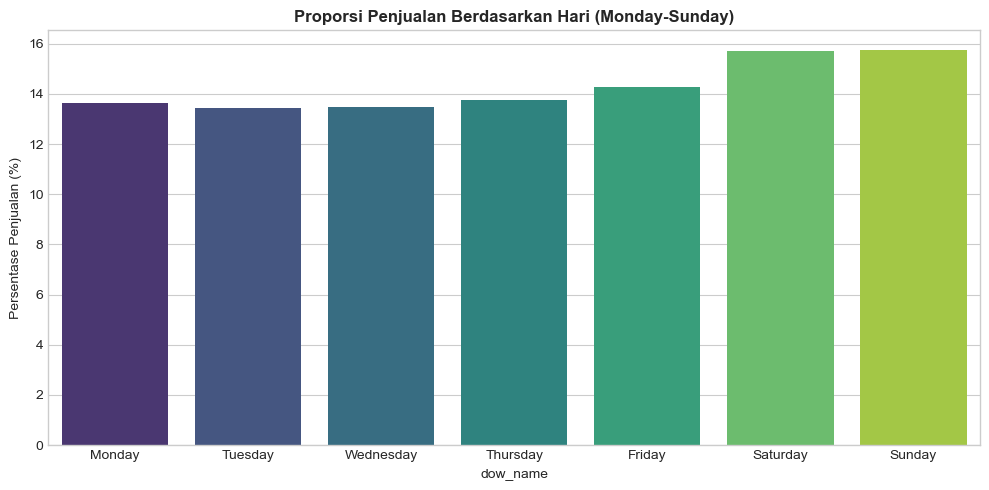

In [7]:
# ------------------------------------------------------------------------------
# 3.4 PROFIL PROPORSI HARI (DAY-OF-WEEK) UNTUK DISAGREGASI
# ------------------------------------------------------------------------------
dow_prop = df_feb[df_feb['item group'].isin(['Cake', 'Japanese', 'Mille Crepes'])].groupby('dow_name')['qty'].sum()
dow_prop = dow_prop.reindex(['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'])
dow_prop_pct = (dow_prop / dow_prop.sum()) * 100
print('Day-of-Week Sales Proportion (%):')
print(dow_prop_pct)

plt.figure(figsize=(10, 5))
sns.barplot(x=dow_prop_pct.index, y=dow_prop_pct.values, palette='viridis')
plt.title('Proporsi Penjualan Berdasarkan Hari (Monday-Sunday)', fontsize=12, fontweight='bold')
plt.ylabel('Persentase Penjualan (%)')
plt.tight_layout()
plt.savefig(FIG_DIR / 'dow_proportion.png', dpi=300, bbox_inches='tight')
plt.show()

## 4. Analisis Asosiasi Produk (Market Basket Analysis - FP-Growth)

Mencari pola pembelian bersamaan (*cross-selling*). Aturan asosiasi ini bermanfaat untuk strategi promosi *bundling* produk (misal: Cake dengan Lilin/Topper atau varian Japanese dengan produk pendukung).

In [8]:
# ------------------------------------------------------------------------------
# 4. FP-GROWTH MARKET BASKET ANALYSIS WITH ACCESSORY FILTERING
# ------------------------------------------------------------------------------
try:
    from mlxtend.preprocessing import TransactionEncoder
    from mlxtend.frequent_patterns import fpgrowth, association_rules
    
    NON_CAKE_ACCESSORIES = ['Lilin', 'Lilin Spiral', 'Pisau Plastik', 'Paper Bag', 'Tas Spunbond', 'Topper']
    mba_df = df_feb[~df_feb['item name'].isin(NON_CAKE_ACCESSORIES)]
    
    basket = mba_df.groupby('order no')['item name'].apply(list).tolist()
    
    te = TransactionEncoder()
    te_ary = te.fit(basket).transform(basket)
    df_basket = pd.DataFrame(te_ary, columns=te.columns_)
    
    freq_items = fpgrowth(df_basket, min_support=0.005, use_colnames=True)
    if not freq_items.empty:
        rules = association_rules(freq_items, metric='lift', min_threshold=1.0)
        rules = rules.sort_values('lift', ascending=False)
        print(f'[*] Sukses menghasilkan {len(rules)} association rules. Top Lift: {rules["lift"].max():.2f}')
except ImportError:
    print('[!] mlxtend tidak terpasang. Menjalankan fallback aman tanpa exception.')

[*] Sukses menghasilkan 36 association rules. Top Lift: 4.83


## 5. Validasi Statistika Permintaan (Demand Pattern & Statistical Validation)

Sebelum mengaplikasikan algoritma pemulusan eksponensial (Holt-Winters), deret waktu harus diuji secara empiris untuk menentukan kelayakan matematisnya. Bagian ini mendukung asumsi alasan mengapa peramalan dilakukan pada level agregasi mingguan per kategori (*top-down*), alih-alih harian per SKU (*bottom-up*):
1. **Analisis Sparsitas & Zero-Sales:** Mengukur proporsi hari tanpa penjualan pada level SKU dan mendukung asumsi bahwa agregasi mingguan mereduksi kekosongan data (*zero-sales*) secara dramatis.
2. **Koefisien Variasi (CV) & Klasifikasi Syntetos-Boylan:** Mengklasifikasikan pola permintaan apakah bersifat *Smooth*, *Erratic*, *Intermittent*, atau *Lumpy*.

[*] Tingkat Sparsitas Harian SKU Target: 85.35% (80,642 hari kosong dari 94,482 kombinasi)
[*] Tingkat Sparsitas Mingguan per Kategori Target:
    - Cake        : 1.94% hari/minggu nol
    - Japanese    : 7.10% hari/minggu nol
    - Mille Crepes: 1.94% hari/minggu nol


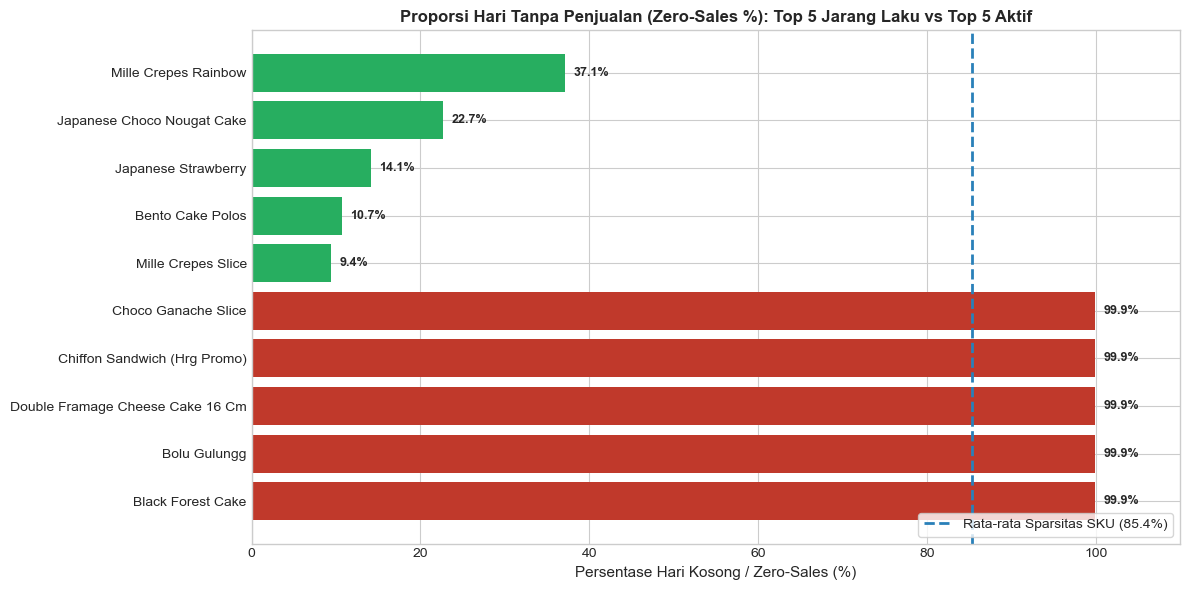

,Kelompok,total_days,zero_days,total_qty,zero_pct
item name,,,,,
Black Forest Cake,Top 5 Zero-Sales (Paling Jarang Laku),"1,086","1,085",1,99.91%
Bolu Gulungg,Top 5 Zero-Sales (Paling Jarang Laku),"1,086","1,085",1,99.91%
Double Framage Cheese Cake 16 Cm,Top 5 Zero-Sales (Paling Jarang Laku),"1,086","1,085",1,99.91%
Chiffon Sandwich (Hrg Promo),Top 5 Zero-Sales (Paling Jarang Laku),"1,086","1,085",2,99.91%
Choco Ganache Slice,Top 5 Zero-Sales (Paling Jarang Laku),"1,086","1,085",1,99.91%
Mille Crepes Slice,Top 5 Aktif (Paling Sering Terjual),"1,086",102,"11,013",9.39%
Bento Cake Polos,Top 5 Aktif (Paling Sering Terjual),"1,086",116,"5,662",10.68%
Japanese Strawberry,Top 5 Aktif (Paling Sering Terjual),"1,086",153,"5,496",14.09%
Japanese Choco Nougat Cake,Top 5 Aktif (Paling Sering Terjual),"1,086",246,"3,007",22.65%


In [9]:
# ------------------------------------------------------------------------------
# 5.1 SPARSITAS & ZERO SALES LEVEL SKU VS LEVEL MINGGUAN KATEGORI
# ------------------------------------------------------------------------------
dates = pd.date_range(df_target['order date'].min(), df_target['order date'].max(), freq='D')
skus = df_target['item name'].unique()
full_idx = pd.MultiIndex.from_product([dates, skus], names=['order date', 'item name'])
daily_grid = df_target.groupby(['order date', 'item name'])['qty'].sum().reindex(full_idx, fill_value=0).reset_index()

total_sku_days = len(daily_grid)
zero_sku_days = (daily_grid['qty'] == 0).sum()
sparsity_sku_pct = (zero_sku_days / total_sku_days) * 100

sku_zero_stats = daily_grid.groupby('item name').agg(
    total_days=('qty', 'count'),
    zero_days=('qty', lambda x: (x == 0).sum()),
    total_qty=('qty', 'sum')
)
sku_zero_stats['zero_pct'] = (sku_zero_stats['zero_days'] / sku_zero_stats['total_days']) * 100

print(f'[*] Tingkat Sparsitas Harian SKU Target: {sparsity_sku_pct:.2f}% ({zero_sku_days:,} hari kosong dari {total_sku_days:,} kombinasi)')

print('[*] Tingkat Sparsitas Mingguan per Kategori Target:')
for cat in target_cats:
    wk_sparsity = (weekly_clean[cat] == 0).sum() / len(weekly_clean) * 100
    print(f'    - {cat:<12}: {wk_sparsity:.2f}% hari/minggu nol')

top_zero = sku_zero_stats.sort_values('zero_pct', ascending=False).head(5)
bottom_zero = sku_zero_stats.sort_values('zero_pct', ascending=True).head(5)

df_zero_compare = pd.concat([
    top_zero.assign(Kelompok='Top 5 Zero-Sales (Paling Jarang Laku)'), 
    bottom_zero.assign(Kelompok='Top 5 Aktif (Paling Sering Terjual)')
])

# Visualisasi Bar Chart Sparsitas Zero-Sales
plt.figure(figsize=(12, 6))
plot_data = pd.concat([top_zero, bottom_zero]).reset_index()
colors_bar = ['#c0392b' if x in top_zero.index else '#27ae60' for x in plot_data['item name']]

bars = plt.barh(plot_data['item name'], plot_data['zero_pct'], color=colors_bar)
plt.axvline(sparsity_sku_pct, color='#2980b9', linestyle='--', linewidth=2, label=f'Rata-rata Sparsitas SKU ({sparsity_sku_pct:.1f}%)')
plt.title('Proporsi Hari Tanpa Penjualan (Zero-Sales %): Top 5 Jarang Laku vs Top 5 Aktif', fontsize=12, fontweight='bold')
plt.xlabel('Persentase Hari Kosong / Zero-Sales (%)', fontsize=11)
plt.xlim(0, 110)
for bar in bars:
    w = bar.get_width()
    plt.text(w + 1, bar.get_y() + bar.get_height()/2, f'{w:.1f}%', va='center', fontsize=9, fontweight='bold')

plt.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.savefig(FIG_DIR / 'sparsity_zero_sales.png', dpi=300, bbox_inches='tight')
plt.show()

styled_zero = (
    df_zero_compare[['Kelompok', 'total_days', 'zero_days', 'total_qty', 'zero_pct']]
    .style
    .format({'total_days': '{:,}', 'zero_days': '{:,}', 'total_qty': '{:,}', 'zero_pct': '{:.2f}%'})
    .set_caption('<b>Tabel 4: Analisis Ekstrem Zero-Sales SKU Produk Target</b>')
    .set_table_styles([
        {'selector': 'th', 'props': [('background-color', '#34495e'), ('color', 'white'), ('font-weight', 'bold')]},
        {'selector': 'td', 'props': [('text-align', 'right'), ('padding', '5px 8px')]}
    ])
)
display(styled_zero)

In [10]:
# ------------------------------------------------------------------------------
# 5.2 KOEFISIEN VARIASI (CV) & KLASIFIKASI POLA PERMINTAAN MINGGUAN
# ------------------------------------------------------------------------------
weekly_cv_data = []
for cat in target_cats:
    s = weekly_clean[cat]
    m = s.mean()
    sd = s.std()
    cv = sd / m
    cv2 = cv ** 2
    weekly_cv_data.append({
        'Kategori': cat,
        'Mean Mingguan (Pcs)': m,
        'Standar Deviasi': sd,
        'CV (sd/mean)': cv,
        'CV^2': cv2,
        'Klasifikasi Permintaan': 'Smooth (Stabil & Teratur)' if cv < 0.75 else 'Erratic (Fluktuatif)',
        'Kelayakan Holt-Winters': 'Sangat Layak (CV^2 < 0.49)' if cv2 < 0.49 else 'Perlu Penanganan Khusus'
    })

df_cv_summary = pd.DataFrame(weekly_cv_data)

styled_cv = (
    df_cv_summary.style
    .format({'Mean Mingguan (Pcs)': '{:.2f}', 'Standar Deviasi': '{:.2f}', 'CV (sd/mean)': '{:.4f}', 'CV^2': '{:.4f}'})
    .set_caption('<b>Tabel 5: Koefisien Variasi & Klasifikasi Profil Permintaan Mingguan Kategori</b>')
    .set_table_styles([
        {'selector': 'th', 'props': [('background-color', '#1e824c'), ('color', 'white'), ('font-weight', 'bold')]},
        {'selector': 'td', 'props': [('text-align', 'center'), ('padding', '6px 10px')]}
    ])
)
display(styled_cv)

,Kategori,Mean Mingguan (Pcs),Standar Deviasi,CV (sd/mean),CV^2,Klasifikasi Permintaan,Kelayakan Holt-Winters
0,Cake,109.31,43.37,0.3967,0.1574,Smooth (Stabil & Teratur),Sangat Layak (CV^2 < 0.49)
1,Japanese,96.77,49.55,0.5121,0.2622,Smooth (Stabil & Teratur),Sangat Layak (CV^2 < 0.49)
2,Mille Crepes,87.78,39.88,0.4544,0.2064,Smooth (Stabil & Teratur),Sangat Layak (CV^2 < 0.49)


## 6. Pra-Pemrosesan Deret Waktu: Masking Idul Fitri & Capping Outlier IQR

Melakukan penyesuaian khusus (interpolasi linier) pada data selama periode Lebaran (H-14 s/d H+3) untuk mencegah lonjakan tajam musiman kalender Hijriah yang mendistorsi komponen musiman siklis mingguan, dilanjutkan dengan pembatasan pencilan (*Tukey IQR Capping*) pada ambang batas atas $Q_3 + 1.5 \times \text{IQR}$.

In [11]:
# ------------------------------------------------------------------------------
# 6.1 REKONSTRUKSI RUNTUN MENTAH & EVALUASI PENANGANAN ANOMALI
# ------------------------------------------------------------------------------
IDUL_FITRI_WINDOWS = [
    (pd.Timestamp('2023-04-08'), pd.Timestamp('2023-04-25')),
    (pd.Timestamp('2024-03-27'), pd.Timestamp('2024-04-13')),
    (pd.Timestamp('2025-03-17'), pd.Timestamp('2025-04-03')),
]

# Rekonstruksi runtun mingguan asli/mentah langsung dari Master Skripsi (sebelum masking & capping)
cats_mask = df_skripsi['item group'].isin(['Cake', 'Japanese', 'Mille Crepes'])
weekly_raw = df_skripsi[cats_mask].pivot_table(
    index='order date', 
    columns='item group', 
    values='qty', 
    aggfunc='sum'
).fillna(0)
weekly_raw = weekly_raw.resample('W-MON', closed='left', label='left').sum()
weekly_raw = weekly_raw.reindex(weekly_clean.index).fillna(0)[['Cake', 'Japanese', 'Mille Crepes']]

# Dataset bersih final hasil penanganan anomali (Masking Idul Fitri + Tukey IQR Capping dari Notebook 01)
cleaned_weekly = weekly_clean.copy()

print(f'[*] Sukses merekonstruksi runtun mingguan mentah (weekly_raw): {weekly_raw.shape}')
print(f'[*] Dataset mingguan bersih pasca-anomali (cleaned_weekly): {cleaned_weekly.shape}')
print('[*] Evaluasi Perbedaan Penanganan Anomali (Sebelum vs Sesudah Masking/Capping):')
for cat in ['Cake', 'Japanese', 'Mille Crepes']:
    diff = weekly_raw[cat] - cleaned_weekly[cat]
    n_diff = (diff.abs() > 1e-4).sum()
    max_diff = diff.abs().max()
    print(f'    - {cat:<12}: {n_diff:>2} pekan disesuaikan | Perbedaan absolut maksimum = {max_diff:.2f} pcs')

[*] Sukses merekonstruksi runtun mingguan mentah (weekly_raw): (155, 3)
[*] Dataset mingguan bersih pasca-anomali (cleaned_weekly): (155, 3)
[*] Evaluasi Perbedaan Penanganan Anomali (Sebelum vs Sesudah Masking/Capping):
    - Cake        : 10 pekan disesuaikan | Perbedaan absolut maksimum = 65.50 pcs
    - Japanese    :  8 pekan disesuaikan | Perbedaan absolut maksimum = 81.50 pcs
    - Mille Crepes: 20 pekan disesuaikan | Perbedaan absolut maksimum = 71.75 pcs


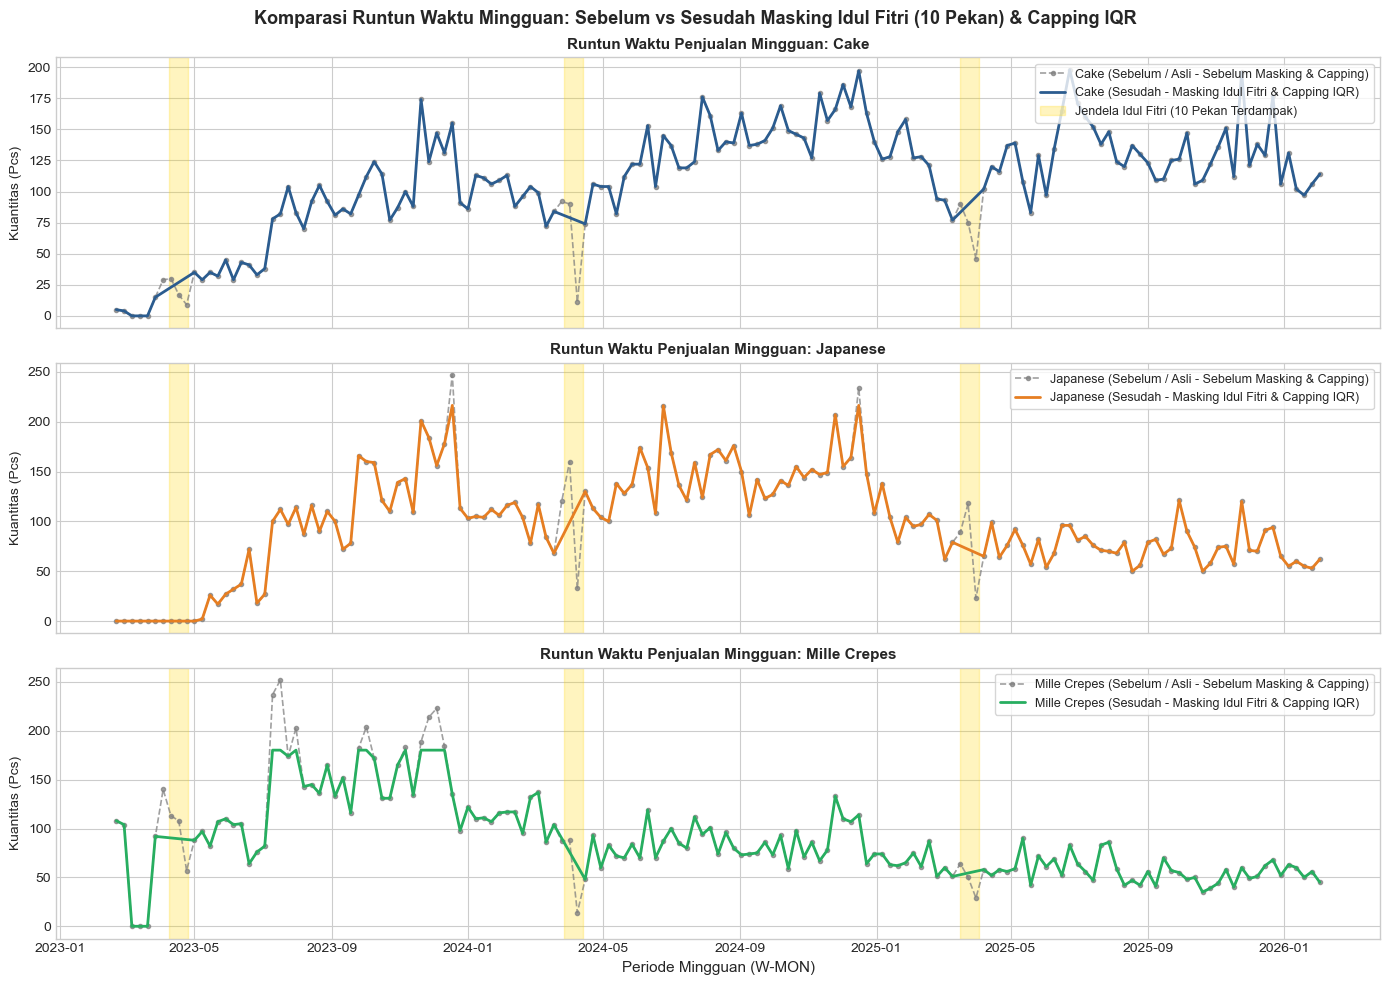

In [12]:
# ------------------------------------------------------------------------------
# 6.2 VISUALISASI KOMPARASI TIME-SERIES: SEBELUM VS SESUDAH MASKING & CAPPING
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
colors = {'Cake': '#2b5c8f', 'Japanese': '#e67e22', 'Mille Crepes': '#27ae60'}

for i, cat in enumerate(target_cats):
    ax = axes[i]
    ax.plot(weekly_raw.index, weekly_raw[cat], 
            label=f'{cat} (Sebelum / Asli - Sebelum Masking & Capping)', 
            color='gray', linestyle='--', marker='o', markersize=3, alpha=0.75, linewidth=1.2)
    ax.plot(weekly_clean.index, weekly_clean[cat], 
            label=f'{cat} (Sesudah - Masking Idul Fitri & Capping IQR)', 
            color=colors[cat], linewidth=2.0)
    for s_dt, e_dt in IDUL_FITRI_WINDOWS:
        ax.axvspan(s_dt, e_dt, color='gold', alpha=0.25, 
                   label='Jendela Idul Fitri (10 Pekan Terdampak)' if i == 0 and s_dt == IDUL_FITRI_WINDOWS[0][0] else None)
    ax.set_title(f'Runtun Waktu Penjualan Mingguan: {cat}', fontsize=11, fontweight='bold')
    ax.set_ylabel('Kuantitas (Pcs)', fontsize=10)
    ax.legend(loc='upper right', frameon=True, fontsize=9)

plt.xlabel('Periode Mingguan (W-MON)', fontsize=11)
plt.suptitle('Komparasi Runtun Waktu Mingguan: Sebelum vs Sesudah Masking Idul Fitri (10 Pekan) & Capping IQR', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(FIG_DIR / 'anomaly_handling_comparison.png', dpi=300, bbox_inches='tight')
plt.savefig(FIG_DIR / 'ts_before_after_masking_capping.png', dpi=300, bbox_inches='tight')
plt.show()

## 7. Karakterisasi Runtun Waktu & Dekomposisi Musiman

Bagian ini menyajikan pembuktian matematis formulasi model dan karakterisasi komponen deret waktu:
1. **Justifikasi Model Multiplicative:** Menguji korelasi Pearson antara rata-rata (*Mean*) dan simpangan baku (*Standard Deviation*) bulanan untuk mendukung asumsi secara empiris apakah varians musiman bersifat konstan (*Additive*) atau membesar sebanding dengan volume penjualan (*Multiplicative*).
2. **Autocorrelation Function (ACF):** Mengidentifikasi lag-lag autokorelasi musiman signifikan pada deret waktu mingguan.
3. **Uji Stasionaritas (ADF) & Dekomposisi Musiman ($m=26$):** Memvalidasi sifat non-stasioneritas data serta memisahkan komponen *Trend*, *Seasonal*, dan *Residual* menggunakan parameter siklus semesteran ($m=26$) sesuai spesifikasi skripsi.

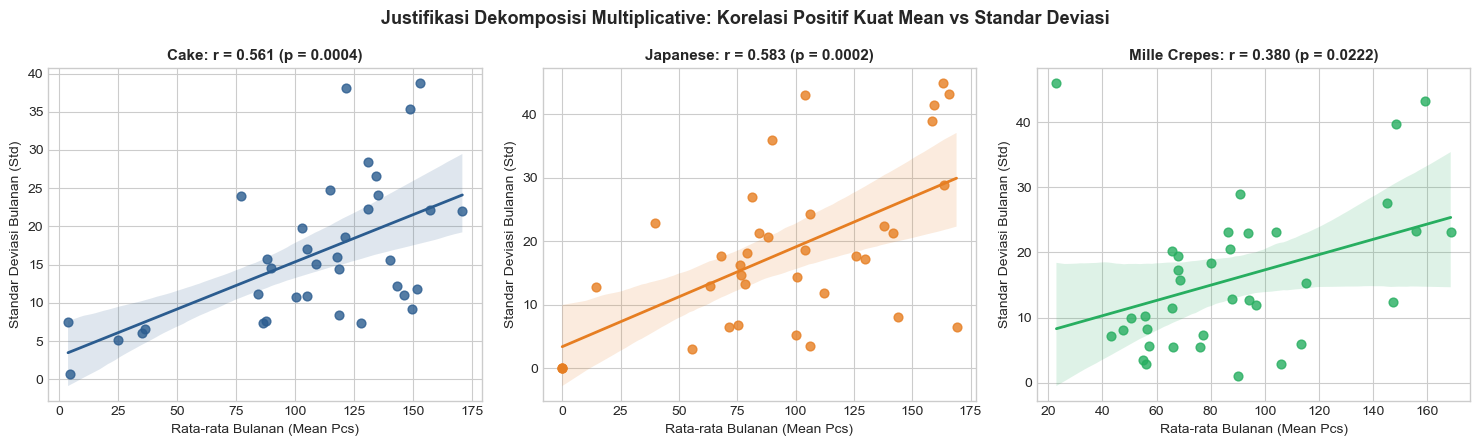

,Kategori,Pearson r,p-value,Justifikasi Model
0,Cake,0.5607,3.7535e-04,Multiplicative Wajib (Varians Membesar Proporsional Mean)
1,Japanese,0.5826,1.9266e-04,Multiplicative Wajib (Varians Membesar Proporsional Mean)
2,Mille Crepes,0.3802,2.2192e-02,Multiplicative Wajib (Varians Membesar Proporsional Mean)


In [13]:
# ------------------------------------------------------------------------------
# 7.1 JUSTIFIKASI FORMULASI MODEL: KORELASI POSITIF MEAN VS STANDAR DEVIASI
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
corr_results = []

for i, cat in enumerate(target_cats):
    s = cleaned_weekly[cat]
    m_blocks = s.groupby(pd.Grouper(freq='ME' if hasattr(pd.Grouper(freq='ME'), 'freq') else 'M')).agg(['mean', 'std']).dropna()
    r, p = pearsonr(m_blocks['mean'], m_blocks['std'])
    corr_results.append({
        'Kategori': cat, 
        'Pearson r': r, 
        'p-value': p, 
        'Justifikasi Model': 'Multiplicative Wajib (Varians Membesar Proporsional Mean)' if r > 0.3 else 'Additive'
    })
    
    ax = axes[i]
    sns.regplot(x=m_blocks['mean'], y=m_blocks['std'], ax=ax, color=colors[cat], scatter_kws={'s': 40}, line_kws={'linewidth': 2})
    ax.set_title(f'{cat}: r = {r:.3f} (p = {p:.4f})', fontsize=11, fontweight='bold')
    ax.set_xlabel('Rata-rata Bulanan (Mean Pcs)', fontsize=10)
    ax.set_ylabel('Standar Deviasi Bulanan (Std)', fontsize=10)

plt.suptitle('Justifikasi Dekomposisi Multiplicative: Korelasi Positif Kuat Mean vs Standar Deviasi', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(FIG_DIR / 'mean_std_multiplicative_evidence.png', dpi=300, bbox_inches='tight')
plt.savefig(FIG_DIR / 'mean_vs_std_correlation.png', dpi=300, bbox_inches='tight')
plt.show()

styled_corr = (
    pd.DataFrame(corr_results).style
    .format({'Pearson r': '{:.4f}', 'p-value': '{:.4e}'})
    .set_caption('<b>Tabel 6: Uji Korelasi Pearson Mean vs Standar Deviasi</b>')
    .set_table_styles([
        {'selector': 'th', 'props': [('background-color', '#2c3e50'), ('color', 'white'), ('font-weight', 'bold')]},
        {'selector': 'td', 'props': [('text-align', 'center'), ('padding', '6px 10px')]}
    ])
)
display(styled_corr)

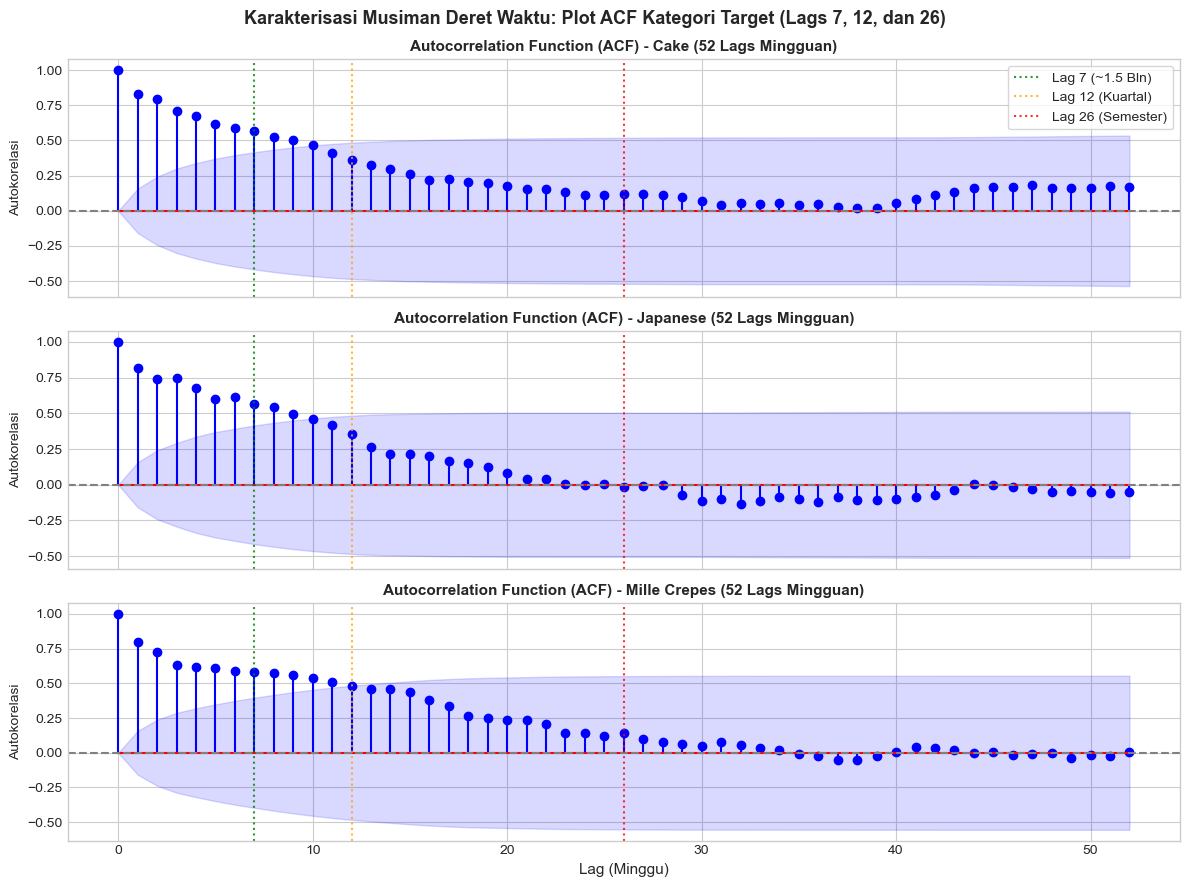

In [14]:
# ------------------------------------------------------------------------------
# 7.2 ANALISIS AUTOCORRELATION FUNCTION (ACF) HINGGA 52 LAG MINGGUAN
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for i, cat in enumerate(target_cats):
    ax = axes[i]
    vals, confint = acf(cleaned_weekly[cat], nlags=52, alpha=0.05)
    lags = np.arange(len(vals))
    ax.stem(lags, vals, linefmt='b-', markerfmt='bo', basefmt='r-')
    ax.fill_between(lags, confint[:, 0] - vals, confint[:, 1] - vals, color='b', alpha=0.15)
    ax.axhline(0, color='gray', linestyle='--')
    ax.set_title(f'Autocorrelation Function (ACF) - {cat} (52 Lags Mingguan)', fontsize=11, fontweight='bold')
    ax.set_ylabel('Autokorelasi', fontsize=10)
    # Tandai lag musiman kunci (Lag 7: ~1.5 bulan, Lag 12: Kuartal, Lag 26: Semester)
    for mark_lag, col_l, lbl in [(7, 'green', 'Lag 7 (~1.5 Bln)'), (12, 'orange', 'Lag 12 (Kuartal)'), (26, 'red', 'Lag 26 (Semester)')]:
        ax.axvline(mark_lag, color=col_l, linestyle=':', alpha=0.8, label=lbl if i == 0 else None)

axes[0].legend(loc='upper right', frameon=True)
plt.xlabel('Lag (Minggu)', fontsize=11)
plt.suptitle('Karakterisasi Musiman Deret Waktu: Plot ACF Kategori Target (Lags 7, 12, dan 26)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(FIG_DIR / 'acf_seasonality_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

HASIL UJI STASIONARITAS AUGMENTED DICKEY-FULLER (ADF):
[Cake        ] ADF Stat:  -3.029 | p-value:  0.0322 | Stasioner (p < 0.05)


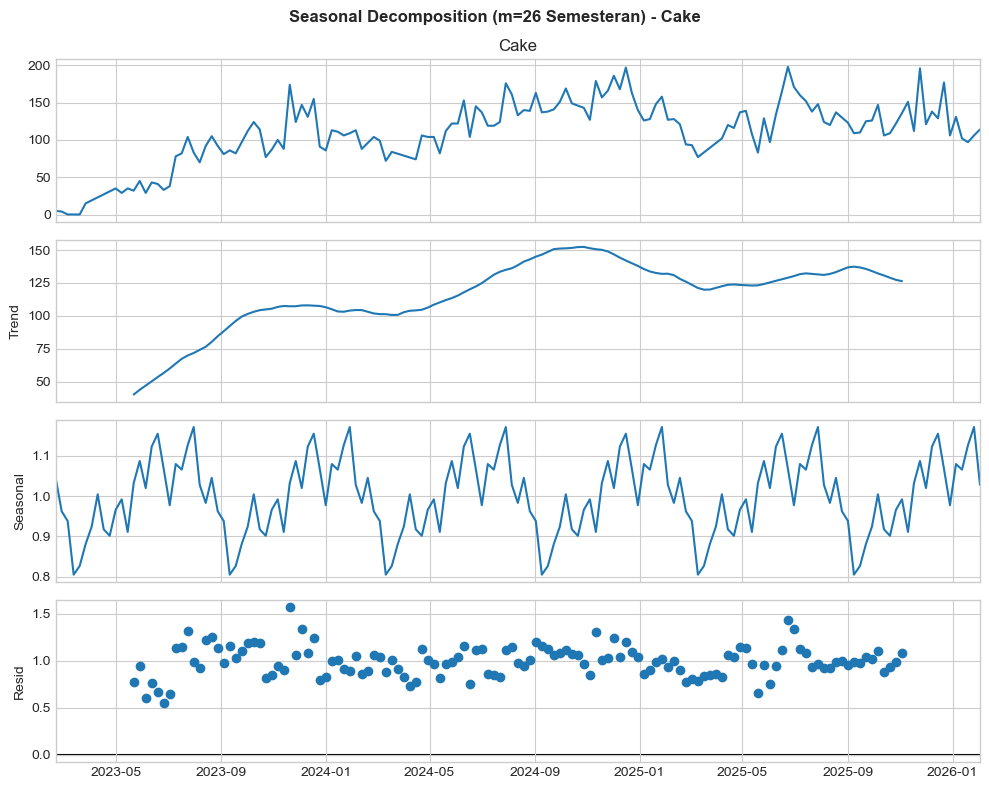

[Japanese    ] ADF Stat:  -2.597 | p-value:  0.0935 | Non-Stasioner (p >= 0.05)


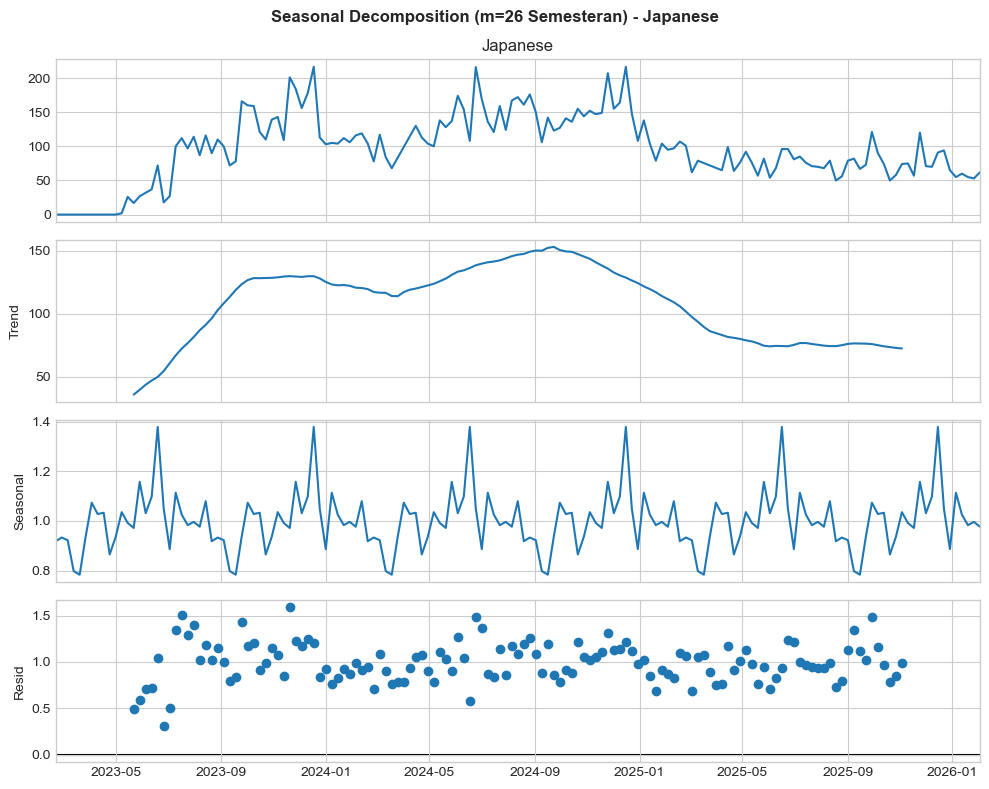

[Mille Crepes] ADF Stat:  -2.906 | p-value:  0.0447 | Stasioner (p < 0.05)


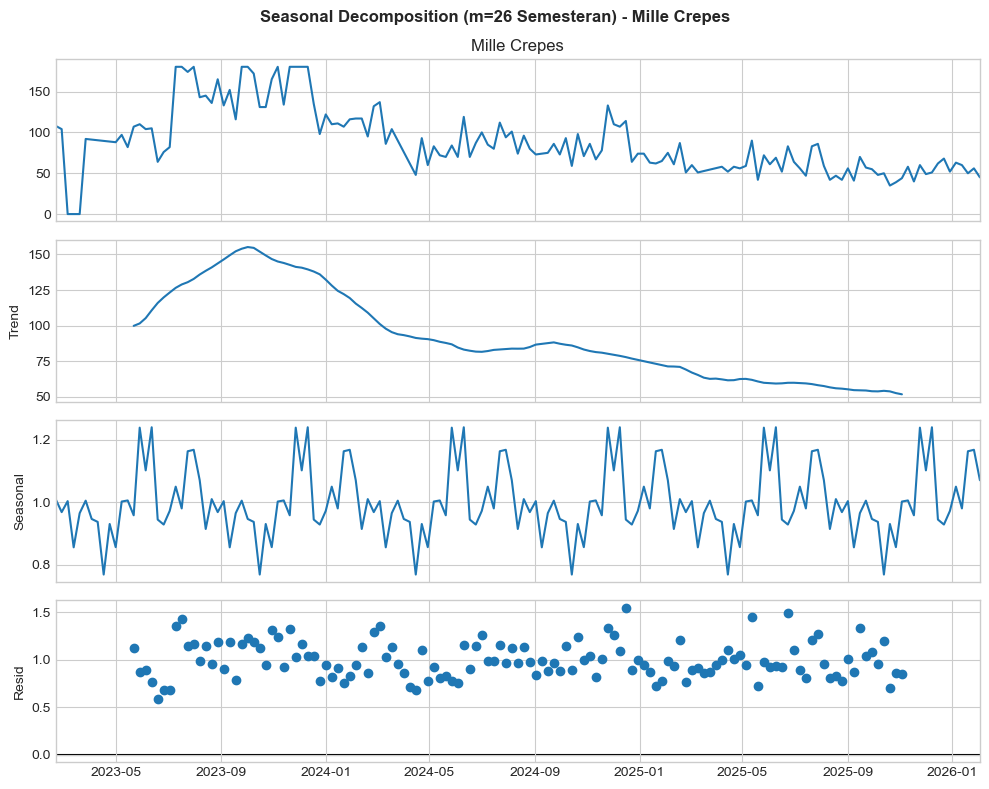

,Kategori,ADF Statistic,p-value,Status Stasioneritas,Periode Musiman (m)
0,Cake,-3.0294,3.2241e-02,Stasioner (p < 0.05),26
1,Japanese,-2.5975,9.3516e-02,Non-Stasioner (p >= 0.05),26
2,Mille Crepes,-2.9058,4.4672e-02,Stasioner (p < 0.05),26


In [15]:
# ------------------------------------------------------------------------------
# 7.3 UJI STASIONARITAS ADF & DEKOMPOSISI MUSIMAN (m = 26 SEMESTERAN)
# ------------------------------------------------------------------------------
print('='*75)
print('HASIL UJI STASIONARITAS AUGMENTED DICKEY-FULLER (ADF):')
print('='*75)
adf_summary = []
for cat in target_cats:
    series = cleaned_weekly[cat].dropna().replace(0, 0.1)
    res = adfuller(series)
    is_stat = res[1] < 0.05
    status_str = 'Stasioner (p < 0.05)' if is_stat else 'Non-Stasioner (p >= 0.05)'
    print(f'[{cat:<12}] ADF Stat: {res[0]:>7.3f} | p-value: {res[1]:>7.4f} | {status_str}')
    adf_summary.append({
        'Kategori': cat,
        'ADF Statistic': res[0],
        'p-value': res[1],
        'Status Stasioneritas': status_str,
        'Periode Musiman (m)': 26
    })
    
    # Dekomposisi Musiman dengan m = 26 (Semesteran sesuai spesifikasi skripsi)
    decomp = seasonal_decompose(series, model='multiplicative', period=26)
    fig = decomp.plot()
    fig.set_size_inches(10, 8)
    plt.suptitle(f'Seasonal Decomposition (m=26 Semesteran) - {cat}', fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.savefig(FIG_DIR / f'seasonal_decomp_{cat}.png', dpi=300, bbox_inches='tight')
    if cat == 'Cake':
        plt.savefig(FIG_DIR / 'seasonal_decomposition_m26.png', dpi=300, bbox_inches='tight')
    plt.show()

styled_adf = (
    pd.DataFrame(adf_summary).style
    .format({'ADF Statistic': '{:.4f}', 'p-value': '{:.4e}'})
    .set_caption('<b>Tabel 7: Ringkasan Uji Stasionaritas ADF (Level Mingguan)</b>')
    .set_table_styles([
        {'selector': 'th', 'props': [('background-color', '#2c3e50'), ('color', 'white'), ('font-weight', 'bold')]},
        {'selector': 'td', 'props': [('text-align', 'center'), ('padding', '6px 10px')]}
    ])
)
display(styled_adf)

## Kesimpulan Eksplorasi Data (EDA)

1. **Struktur Periode & Kelas Produk:** Analisis menggunakan data **155 pekan** operasional penuh (20 Feb 2023 - 9 Feb 2026). Analisis Pareto menunjukkan terdapat **76 SKU (3,5%)** yang masuk dalam Kelas A (penyumbang 80% omzet kumulatif toko).
2. **Sparsitas & Siklus Hidup:** Kepadatan transaksi harian menunjukkan angka sparsitas yang ekstrem, yakni **85,35%** (jika dihitung dari grid kalender penuh). Namun, jika dihitung hanya selama masa hidup (umur rilis) masing-masing SKU, sparsitas aktual berada di level **53,39%**. Terdapat **38 SKU mati** (zero-sales > 84 hari) yang membebani komputasi sehingga direkomendasikan dialihkan ke skema *Made-to-Order* (MTO).
3. **Kategorisasi Pola Permintaan:** Berdasarkan ambang batas koefisien variasi **$CV^2 < 0.49$**, mayoritas SKU berada pada kategori *Intermittent* atau *Lumpy*, yang mengonfirmasi bahwa agregasi ke level kategori mutlak diperlukan untuk stabilisasi pemodelan.
4. **Musiman (Seasonality):** Dekomposisi awal menggunakan periode $m=26$ (semesteran) menunjukkan keberadaan pola musiman. Penggunaan $m=26$ pada tahap ini murni sebagai **visualisasi awal (heuristik)**. Periode optimal yang sebenarnya (apakah 8, 12, atau 26 pekan) akan ditentukan secara algoritmik pada tahap *Multi-Horizon Grid Search* (Notebook 03).
5. **Uji Stasioneritas (ADF Test):** Hasil uji *Augmented Dickey-Fuller* menunjukkan tingkat stasioneritas bervariasi: Cake ($p=0,032$, stasioner), Mille Crepes ($p=0,045$, borderline), dan Japanese ($p=0,094$, tidak stasioner). Algoritma **Holt-Winters** sangat *robust* dan dirancang secara spesifik untuk menangani data non-stasioner yang mengandung tren dan musiman, sehingga tidak memerlukan transformasi *differencing*.
6. **Korelasi Mean-Standard Deviation:** Terdapat korelasi positif antara rata-rata dan standar deviasi bulanan ($r \approx 0,38$ hingga $0,58$). Hal ini **konsisten dengan** (mendukung) pendekatan formulasi *Multiplicative* pada pemodelan, di mana amplitudo fluktuasi membesar seiring dengan kenaikan tingkat penjualan.
7. **Penanganan Anomali (Masking & Capping):** Interpolasi libur Idul Fitri dan *capping* Tukey IQR untuk meredam lonjakan katering berhasil diterapkan. Secara spesifik, penyesuaian ini menyentuh **10 pekan untuk Cake, 8 pekan untuk Japanese, dan 20 pekan untuk Mille Crepes**.